# IA102 — Apprentissage profond avec PyTorch

## Notebook 0 — Révision de IA101 et motivation

**Calcul Québec** · Atelier en ligne · Durée de ce notebook : 15 minutes

L'atelier présente les fondamentaux de l'apprentissage profond : construire des réseaux de neurones capables d'apprendre automatiquement à partir de données brutes, et les entraîner avec PyTorch. Il suit le programme annoncé :

1. **Révision de IA101** (ce notebook)
2. **Introduction aux réseaux de neurones** (notebook 1)
3. **Entraînement de réseaux de neurones avec PyTorch** (notebooks 2, 3 et 4)
4. **Introduction à l'entraînement haute performance** (notebook 5)

### Objectifs de l'atelier

| # | Objectif annoncé | À la fin de l'atelier, les participants seront en mesure de… | Notebooks |
| --- | --- | --- | --- |
| O1 | Comprendre les bases de l'apprentissage profond | expliquer le neurone artificiel, les fonctions d'activation, la rétropropagation, et la raison d'être des réseaux profonds | 0, 1 |
| O2 | Créer des réseaux de neurones | définir un réseau avec `nn.Sequential` ou `nn.Module`, choisir la couche de sortie et la fonction de perte, construire un réseau convolutif | 1, 3 |
| O3 | Entraîner des modèles avec PyTorch | écrire la boucle d'entraînement, utiliser `Dataset` et `DataLoader`, suivre et améliorer la généralisation (régularisation, transfert d'apprentissage) | 2, 3, 4 |
| O4 | S'initier à l'entraînement haute performance | utiliser un GPU, optimiser le chargement des données, employer la précision mixte et les points de contrôle, lancer un entraînement multi-GPU et le soumettre avec Slurm | 3, 5 |

### Prérequis

Statistiques, programmation Python, analyse de données avec NumPy, pandas et Matplotlib, et bases de l'apprentissage machine (IA101, PYT101, PYT102, DAT201, DAT203 ou équivalent).

### Déroulement (13 h 30 à 16 h 30)

| Heure | Notebook | Partie du programme | Contenu |
| --- | --- | --- | --- |
| 13 h 30 | 0 | Révision de IA101 | Cycle d'apprentissage, généralisation ; limites des modèles linéaires |
| 13 h 45 | 1 | Introduction aux réseaux de neurones | Neurone, activations, tenseurs, autograd, rétropropagation, `nn.Module` |
| 14 h 15 | 2 | Entraînement avec PyTorch | Boucle d'entraînement, taux d'apprentissage, optimiseurs |
| 14 h 45 | *Pause* | | |
| 14 h 55 | 3 | Entraînement avec PyTorch | Réseaux convolutifs, `DataLoader`, mini-lots, GPU |
| 15 h 30 | 4 | Entraînement avec PyTorch | Surapprentissage, régularisation, transfert d'apprentissage |
| 15 h 50 | 5 | Entraînement haute performance | Débit, chargement des données, précision mixte, points de contrôle, multi-GPU, Slurm |
| 16 h 20 | Synthèse | | Test de positionnement final, questions |

Le notebook **bonus** (Transformers et mécanisme d'attention) est proposé en étude autonome.

### Conventions

| Mention | Signification |
| --- | --- |
| **Prédiction** | Formuler une hypothèse avant d'exécuter la cellule. |
| **Exercice** | Compléter les lignes marquées `# À COMPLÉTER` ; une solution repliable suit. |
| **Question de vérification** | Question à choix multiples avec rétroaction immédiate. |
| **À retenir** | Synthèse du notebook. |

### Test de positionnement (2 minutes)

Répondez brièvement dans la cellule suivante. Le même test est repris à la fin de l'atelier (notebook 5).

1. Que calcule un neurone artificiel à partir de ses entrées ?
2. Pourquoi une fonction d'activation non linéaire est-elle nécessaire ?
3. Citez, dans l'ordre, les étapes de la boucle d'entraînement PyTorch.
4. Pourquoi un réseau convolutif convient-il mieux aux images qu'un réseau entièrement connecté ?
5. Citez deux moyens d'accélérer un entraînement sur une grappe de calcul.

In [ ]:
# Réponses au début de l'atelier
# 1.
# 2.
# 3.
# 4.
# 5.

In [4]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

print("Version de PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

## 1. Révision de IA101

### Le cycle d'apprentissage

| Étape | IA101 (scikit-learn) | IA102 (PyTorch) |
| --- | --- | --- |
| **Modèle** | Fonction paramétrée, par exemple $\hat{y} = a\,x + b$ | Réseau de neurones : des milliers à des millions de paramètres |
| **Perte** | EQM (régression), entropie croisée (classification) | Les mêmes : `nn.MSELoss`, `nn.CrossEntropyLoss` |
| **Optimisation** | Cachée dans `.fit()` | Écrite explicitement : boucle de descente de gradient |
| **Gradient** | Dérivé à la main pour l'EQM : $\partial L / \partial a = \frac{2}{n}\sum (\hat{y}_i - y_i)\,x_i$ | Calculé automatiquement par **autograd** (rétropropagation) |
| **Évaluation** | Ensemble de test, validation croisée | Ensembles de validation et de test |

### La règle de mise à jour

$$\theta \leftarrow \theta - \eta\,\nabla_{\theta} L(\theta)$$

où $\theta$ désigne l'ensemble des paramètres et $\eta$ le taux d'apprentissage. Un taux trop petit ralentit la convergence ; un taux trop grand la fait diverger.

### La généralisation

| Situation | Entraînement | Validation | Action |
| --- | --- | --- | --- |
| Sous-apprentissage | Faible | Faible | Modèle plus expressif, plus d'itérations |
| Surapprentissage | Élevée | Nettement plus faible | Régularisation, plus de données, arrêt précoce |
| Bon ajustement | Élevée | Proche de l'entraînement | — |

Règle méthodologique : les réglages se choisissent sur la validation ; l'ensemble de test ne sert qu'à l'évaluation finale.

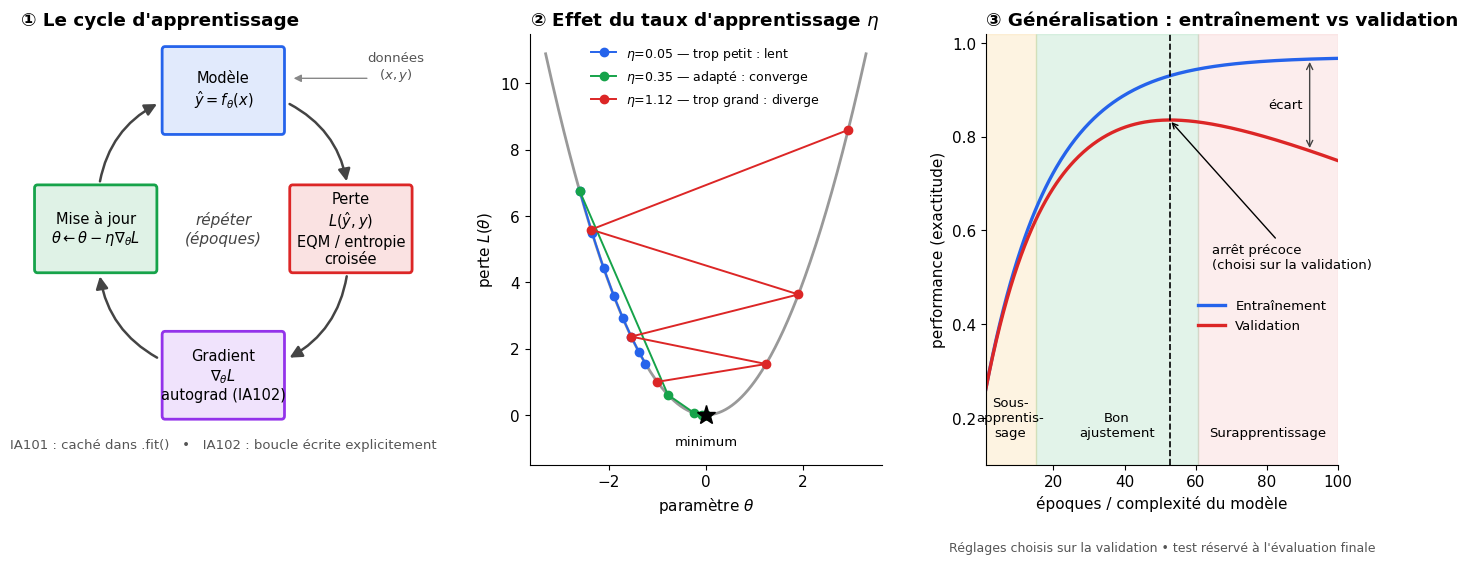

In [ ]:
# @title
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
C1,C2,C3,C4="#2563eb","#16a34a","#dc2626","#9333ea"
fig=plt.figure(figsize=(17,5.6))
gs=fig.add_gridspec(1,3,width_ratios=[1.15,1,1],wspace=0.28)

# --- (a) cycle
ax=fig.add_subplot(gs[0]); ax.set_xlim(-0.4,10.4); ax.set_ylim(-0.6,10); ax.axis("off")
ax.set_title("① Le cycle d'apprentissage",fontweight="bold",loc="left")
boxes={"Modèle":(5,8.6,"Modèle\n$\\hat{y}=f_\\theta(x)$",C1),
       "Perte":(8.4,5.2,"Perte\n$L(\\hat{y},y)$\nEQM / entropie\ncroisée",C3),
       "Gradient":(5,1.6,"Gradient\n$\\nabla_\\theta L$\nautograd (IA102)",C4),
       "MAJ":(1.6,5.2,"Mise à jour\n$\\theta\\leftarrow\\theta-\\eta\\nabla_\\theta L$",C2)}
for k,(x,y,t,c) in boxes.items():
    w,h=3.1,2.0
    ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle="round,pad=0.08",fc=c+"22",ec=c,lw=2))
    ax.text(x,y,t,ha="center",va="center",fontsize=10.5)
def arr(p,q,rad=-0.25):
    ax.add_patch(FancyArrowPatch(p,q,connectionstyle=f"arc3,rad={rad}",arrowstyle="-|>",mutation_scale=18,lw=1.8,color="#444"))
arr((6.7,8.3),(8.3,6.3)); arr((8.3,4.1),(6.7,2.0)); arr((3.3,2.0),(1.7,4.1)); arr((1.7,6.3),(3.3,8.3))
ax.text(5,5.2,"répéter\n(époques)",ha="center",va="center",fontsize=11,style="italic",color="#444")
ax.text(5,-0.2,"IA101 : caché dans .fit()   •   IA102 : boucle écrite explicitement",ha="center",fontsize=9.5,color="#555")
ax.text(9.6,8.9,"données\n$(x,y)$",ha="center",fontsize=9.5,color="#555")
ax.annotate("",xy=(6.8,8.9),xytext=(8.9,8.9),arrowprops=dict(arrowstyle="-|>",color="#888"))

# --- (b) learning rate
ax=fig.add_subplot(gs[1])
ax.set_title("② Effet du taux d'apprentissage $\\eta$",fontweight="bold",loc="left")
L=lambda t:t**2; g=lambda t:2*t
th=np.linspace(-3.3,3.3,300); ax.plot(th,L(th),color="#999",lw=2,zorder=1)
for eta,c,lab in [(0.05,C1,"trop petit : lent"),(0.35,C2,"adapté : converge"),(1.12,C3,"trop grand : diverge")]:
    t=[-2.6 if eta!=1.12 else -1.0]
    for _ in range(7 if eta!=1.12 else 5): t.append(t[-1]-eta*g(t[-1]))
    t=np.array(t); t=t[np.abs(t)<3.3]
    ax.plot(t,L(t),"o-",color=c,ms=6,lw=1.4,label=f"$\\eta$={eta} — {lab}",zorder=3)
ax.plot(0,0,"k*",ms=14,zorder=4); ax.text(0,-0.9,"minimum",ha="center",fontsize=9.5)
ax.set_xlabel("paramètre $\\theta$"); ax.set_ylabel("perte $L(\\theta)$")
ax.set_ylim(-1.5,11.5); ax.legend(fontsize=9,loc="upper center",frameon=False)
ax.spines[["top","right"]].set_visible(False)

# --- (c) generalisation
ax=fig.add_subplot(gs[2])
ax.set_title("③ Généralisation : entraînement vs validation",fontweight="bold",loc="left")
e=np.linspace(1,100,300)
tr=0.97-0.75*np.exp(-e/18)
va=0.88-0.66*np.exp(-e/16)-0.13*(np.log1p(np.exp((e-40)/8))*8/60)**1.3
ax.plot(e,tr,color=C1,lw=2.4,label="Entraînement")
ax.plot(e,va,color=C3,lw=2.4,label="Validation")
best=e[np.argmax(va)]
best=e[np.argmax(va)]
ax.axvspan(1,15,color="#f59e0b",alpha=.12); ax.axvspan(15,best+8,color=C2,alpha=.12); ax.axvspan(best+8,100,color=C3,alpha=.08)
ax.text(8,0.16,"Sous-\napprentis-\nsage",ha="center",fontsize=9.5)
ax.text((15+best+8)/2,0.16,"Bon\najustement",ha="center",fontsize=9.5)
ax.text((best+108)/2,0.16,"Surapprentissage",ha="center",fontsize=9.5)
ax.axvline(best,ls="--",color="k",lw=1.2)
ax.annotate("arrêt précoce\n(choisi sur la validation)",xy=(best,va.max()),xytext=(best+12,0.52),fontsize=9.5,
            arrowprops=dict(arrowstyle="->",color="k"))
ax.annotate("",xy=(92,tr[-25]),xytext=(92,va[-25]),arrowprops=dict(arrowstyle="<->",color="#444"))
ax.text(90,(tr[-25]+va[-25])/2,"écart",ha="right",va="center",fontsize=9.5)
ax.set_xlabel("époques / complexité du modèle"); ax.set_ylabel("performance (exactitude)")
ax.set_ylim(0.1,1.02); ax.set_xlim(1,100); ax.legend(loc="lower right",fontsize=9.5,frameon=False,bbox_to_anchor=(1,0.28))
ax.spines[["top","right"]].set_visible(False)
ax.text(0.5,-0.2,"Réglages choisis sur la validation • test réservé à l'évaluation finale",ha="center",fontsize=9,color="#555",transform=ax.transAxes)

fig.savefig("revision_ia101.png",dpi=200,bbox_inches="tight"); fig.savefig("revision_ia101.svg",bbox_inches="tight")

In [ ]:
quiz("Dans la règle θ ← θ − η ∇L(θ), pourquoi soustrait-on le gradient ?",
     ["Parce que le gradient indique la direction de plus forte augmentation de la perte",
      "Pour augmenter la perte", "Pour normaliser les paramètres"],
     0, "On se déplace dans la direction opposée au gradient pour faire diminuer la perte.")

In [ ]:
quiz("Exactitude d'entraînement : 99 %, exactitude de validation : 72 %. Quelle action est la plus appropriée ?",
     ["Augmenter la taille du réseau", "Régulariser ou ajouter des données", "Évaluer sur l'ensemble de test pour choisir les réglages"],
     1, "L'écart indique un surapprentissage : régularisation, augmentation de données, arrêt précoce.")

## 2. Motivation : les limites des modèles linéaires

Deux groupes de points forment des **cercles concentriques**.

**Prédiction.** Une régression logistique trace une frontière linéaire. Quelle exactitude obtiendra-t-elle ?

In [ ]:
X, y = make_circles(n_samples=600, noise=0.08, factor=0.45, random_state=0)
logreg = LogisticRegression().fit(X, y)
print(f"Exactitude de la régression logistique : {logreg.score(X, y):.0%}")

Environ 50 %, soit le hasard : aucune droite ne sépare un disque de l'anneau qui l'entoure. En IA101, il aurait fallu **construire à la main** une variable adaptée (par exemple $x_1^2 + x_2^2$). Un réseau de neurones **apprend lui-même** les représentations utiles.

Le réseau ci-dessous comporte deux couches cachées de 16 neurones. Son fonctionnement est détaillé dans les notebooks 1 et 2.

In [6]:
torch.manual_seed(0)
Xt = torch.tensor(X, dtype=torch.float32)
yt = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

reseau = torch.nn.Sequential(torch.nn.Linear(2, 16), torch.nn.ReLU(),
                             torch.nn.Linear(16, 16), torch.nn.ReLU(),
                             torch.nn.Linear(16, 1))
optimiseur = torch.optim.Adam(reseau.parameters(), lr=0.03)
perte_fn = torch.nn.BCEWithLogitsLoss()
for epoque in range(300):
    optimiseur.zero_grad()
    perte = perte_fn(reseau(Xt), yt)
    perte.backward()
    optimiseur.step()

with torch.no_grad():
    exactitude = ((reseau(Xt) > 0).float() == yt).float().mean().item()
print(f"Exactitude du réseau de neurones : {exactitude:.0%}")

Exactitude du réseau de neurones : 100%


In [ ]:
#@title
xx, yy = np.meshgrid(np.linspace(-1.4, 1.4, 300), np.linspace(-1.4, 1.4, 300))
grille = np.c_[xx.ravel(), yy.ravel()]
with torch.no_grad():
    z_reseau = (reseau(torch.tensor(grille, dtype=torch.float32)) > 0).numpy().reshape(xx.shape)
z_logreg = logreg.predict(grille).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, z, titre in [(axes[0], z_logreg, f"Régression logistique : {logreg.score(X, y):.0%}"),
                     (axes[1], z_reseau, f"Réseau de neurones : {exactitude:.0%}")]:
    ax.contourf(xx, yy, z, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(titre, fontweight="bold"); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Frontière linéaire et frontière apprise par un réseau", y=1.02); plt.show()

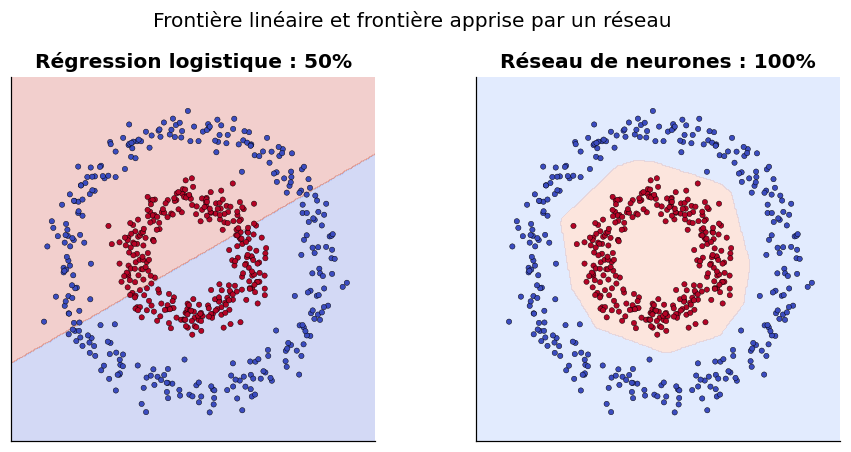

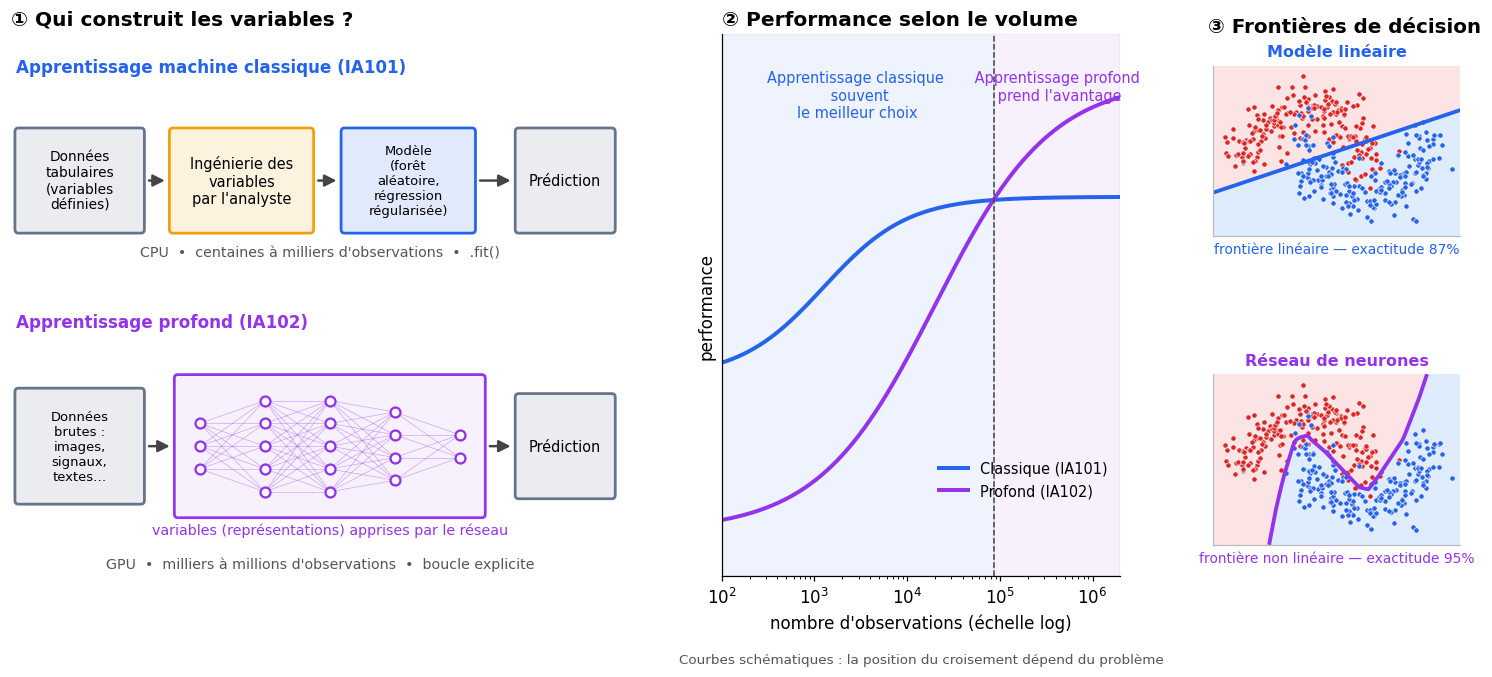

In [13]:
#@title
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
C1,C2,C3,C4,GR="#2563eb","#16a34a","#dc2626","#9333ea","#f59e0b"
fig=plt.figure(figsize=(17,6.4))
gs=fig.add_gridspec(2,3,width_ratios=[1.55,1.0,0.62],wspace=0.22,hspace=0.32)

# --- (a) pipelines
ax=fig.add_subplot(gs[:,0]); ax.set_xlim(0,12.6); ax.set_ylim(0,10); ax.axis("off")
ax.set_title("① Qui construit les variables ?",fontweight="bold",loc="left")
def box(x,y,w,h,t,c,fs=10):
    ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle="round,pad=0.07",fc=c+"22",ec=c,lw=1.8))
    ax.text(x,y,t,ha="center",va="center",fontsize=fs)
def arr(x1,x2,y):
    ax.add_patch(FancyArrowPatch((x1,y),(x2,y),arrowstyle="-|>",mutation_scale=16,lw=1.6,color="#444"))
# classique
ax.text(0.1,9.3,"Apprentissage machine classique (IA101)",fontweight="bold",color=C1,fontsize=11)
yA=7.3
box(1.4,yA,2.5,1.8,"Données\ntabulaires\n(variables\ndéfinies)","#64748b",9)
box(4.7,yA,2.8,1.8,"Ingénierie des\nvariables\npar l'analyste 👤".replace(" 👤",""),GR,9.5)
box(8.1,yA,2.6,1.8,"Modèle\n(forêt\naléatoire,\nrégression\nrégularisée)",C1,8.6)
box(11.3,yA,1.9,1.8,"Prédiction","#64748b",9.5)
arr(2.75,3.2,yA); arr(6.2,6.7,yA); arr(9.5,10.25,yA)
ax.text(6.3,5.9,"CPU  •  centaines à milliers d'observations  •  .fit()",ha="center",fontsize=9.3,color="#555")
# profond
ax.text(0.1,4.6,"Apprentissage profond (IA102)",fontweight="bold",color=C4,fontsize=11)
yB=2.4
box(1.4,yB,2.5,2.0,"Données\nbrutes :\nimages,\nsignaux,\ntextes…","#64748b",8.6)
# reseau
x0,x1=3.4,9.6
ax.add_patch(FancyBboxPatch((x0,yB-1.25),x1-x0,2.5,boxstyle="round,pad=0.07",fc=C4+"12",ec=C4,lw=1.8))
layers=[3,5,5,4,2]; xs=np.linspace(x0+0.45,x1-0.45,len(layers))
pts=[[(xx,yB+(i-(n-1)/2)*0.42) for i in range(n)] for xx,n in zip(xs,layers)]
for a,b in zip(pts[:-1],pts[1:]):
    for p in a:
        for q in b: ax.plot([p[0],q[0]],[p[1],q[1]],color=C4,lw=0.4,alpha=.45)
for L in pts:
    for p in L: ax.plot(*p,"o",ms=6.5,mfc="white",mec=C4,mew=1.5)
ax.text((x0+x1)/2,yB-1.62,"variables (représentations) apprises par le réseau",ha="center",fontsize=9.3,color=C4)
box(11.3,yB,1.9,1.8,"Prédiction","#64748b",9.5)
arr(2.75,3.3,yB); arr(9.7,10.25,yB)
ax.text(6.3,0.15,"GPU  •  milliers à millions d'observations  •  boucle explicite",ha="center",fontsize=9.3,color="#555")

# --- (b) data volume
ax=fig.add_subplot(gs[:,1])
ax.set_title("② Performance selon le volume",fontweight="bold",loc="left")
n=np.logspace(2,6.3,300); x=np.log10(n)
clas=0.62+0.2/(1+np.exp(-(x-3.1)*2.2))
deep=0.45+0.5/(1+np.exp(-(x-4.3)*1.6))
ax.plot(n,clas,color=C1,lw=2.6,label="Classique (IA101)")
ax.plot(n,deep,color=C4,lw=2.6,label="Profond (IA102)")
xc=n[np.argmin(np.abs(clas-deep)[50:])+50]
ax.axvspan(1e2,xc,color=C1,alpha=.07); ax.axvspan(xc,n[-1],color=C4,alpha=.07)
ax.axvline(xc,ls="--",color="#444",lw=1)
ax.text(np.sqrt(1e2*xc),0.96,"Apprentissage classique \n souvent\nle meilleur choix",ha="center",va="top",fontsize=9.5,color=C1)
ax.text(np.sqrt(xc*n[-1]),0.96," Apprentissage profond \n prend l'avantage",ha="center",va="top",fontsize=9.5,color=C4)
ax.set_xscale("log"); ax.set_xlim(1e2,n[-1]); ax.set_ylim(0.4,1.0)
ax.set_xlabel("nombre d'observations (échelle log)"); ax.set_ylabel("performance")
ax.set_yticks([]); ax.legend(loc="lower right",frameon=False,fontsize=9.5,bbox_to_anchor=(1,0.12))
ax.spines[["top","right"]].set_visible(False)
ax.text(0.5,-0.16,"Courbes schématiques : la position du croisement dépend du problème",transform=ax.transAxes,ha="center",fontsize=8.8,color="#555")

# --- (c) boundaries
X,y=make_moons(400,noise=0.22,random_state=0)
mods=[("Modèle linéaire",LogisticRegression().fit(X,y),C1,"frontière linéaire"),
      ("Réseau de neurones",MLPClassifier((32,32),max_iter=3000,random_state=0).fit(X,y),C4,"frontière non linéaire")]
xx,yy=np.meshgrid(np.linspace(-1.6,2.6,300),np.linspace(-1.2,1.7,300))
for k,(name,m,c,sub) in enumerate(mods):
    ax=fig.add_subplot(gs[k,2])
    Z=m.predict_proba(np.c_[xx.ravel(),yy.ravel()])[:,1].reshape(xx.shape)
    ax.contourf(xx,yy,Z,levels=[0,.5,1],colors=["#fde2e2","#dbeafe"],alpha=.9)
    ax.contour(xx,yy,Z,levels=[.5],colors=c,linewidths=2.5)
    ax.scatter(*X[y==0].T,s=12,c=C3,edgecolor="white",lw=.4)
    ax.scatter(*X[y==1].T,s=12,c=C1,edgecolor="white",lw=.4)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(-1.6,2.6); ax.set_ylim(-1.2,1.7); ax.set_aspect('equal')
    ax.set_title(name,loc="center",fontsize=10.5,color=c,fontweight="bold")
    if k==0: ax.text(-0.02,1.2,"③ Frontières de décision",transform=ax.transAxes,fontsize=13,fontweight="bold")
    ax.text(0.5,-0.1,f"{sub} — exactitude {m.score(X,y):.0%}",transform=ax.transAxes,ha="center",fontsize=9,color=c)
    for s in ax.spines.values(): s.set_color("#bbb")
fig.savefig("ml_vs_dl.png",dpi=200,bbox_inches="tight"); fig.savefig("ml_vs_dl.svg",bbox_inches="tight")

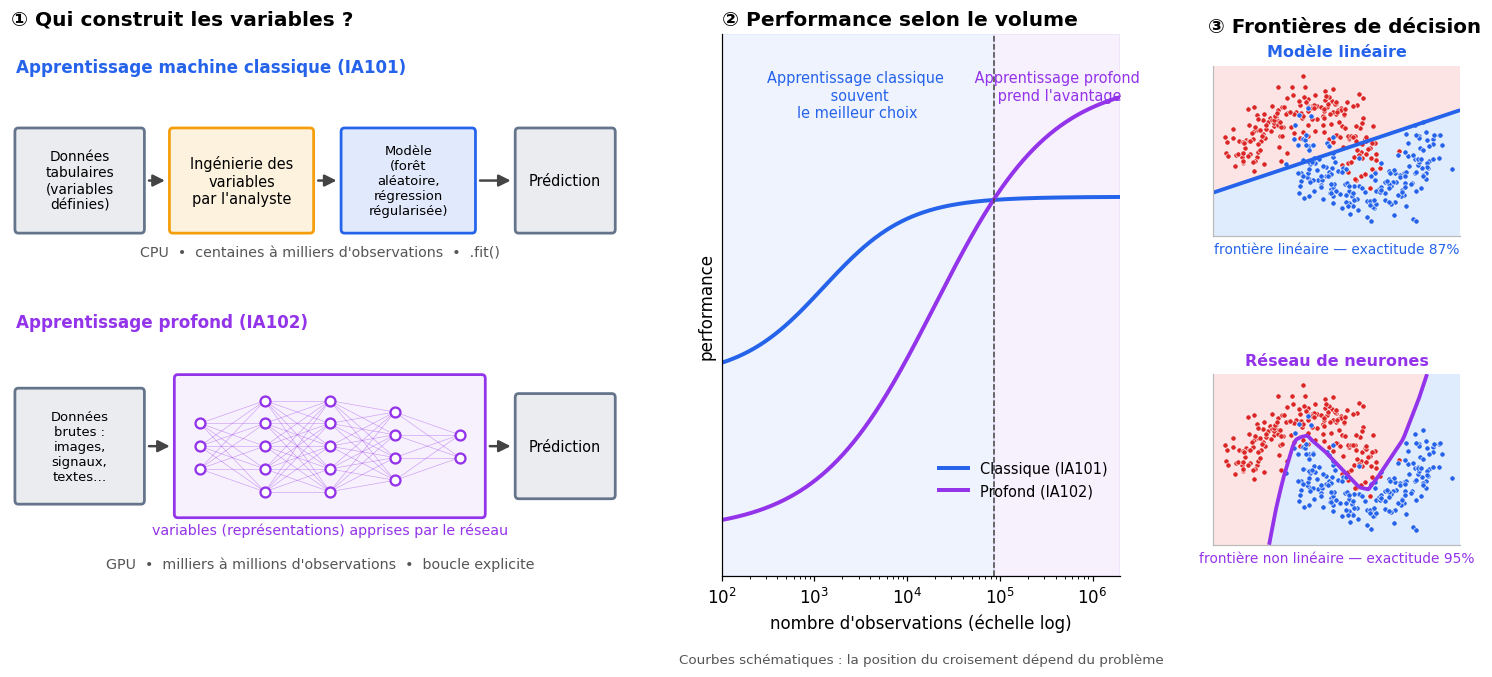

### Quand recourir à l'apprentissage profond ?

| Critère | Apprentissage machine classique (IA101) | Apprentissage profond (IA102) |
| --- | --- | --- |
| Type de données | Tableaux de variables bien définies | Données brutes : images, signaux, textes, séquences |
| Variables | Construites par l'analyste | **Apprises** par le réseau |
| Volume de données | Centaines à milliers d'observations | Milliers à millions d'observations |
| Matériel | Un processeur suffit | **GPU** fortement recommandé |
| Contrôle de l'entraînement | Encapsulé dans `.fit()` | Boucle écrite par l'utilisateur, entièrement paramétrable |

Pour des données tabulaires de taille modeste, les méthodes d'IA101 (forêts aléatoires, régression régularisée) restent souvent le meilleur choix.

## À retenir

- Le cycle **modèle → perte → optimisation → évaluation** est le même qu'en IA101 ; PyTorch rend l'optimisation explicite et calcule les gradients automatiquement.
- Les modèles linéaires ne produisent que des frontières linéaires ; **un réseau de neurones apprend des représentations non linéaires**.

**Notebook suivant :** 1 — Introduction aux réseaux de neurones.